<a href="https://colab.research.google.com/github/nr868848-stack/Advanced_SQL_Ecommerce_Analysis/blob/main/Advanced_SQL_Ecommerce_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import sqlite3

# Establish connection to the database
conn = sqlite3.connect("advanced_ecommerce.db")

# Query total sales per product category
query = """
SELECT
    p.category,
    SUM(oi.quantity * p.price) AS total_sales
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
GROUP BY p.category
ORDER BY total_sales DESC;
"""

df_sales = pd.read_sql_query(query, conn)
display(df_sales)

In [ ]:

import sqlite3
import pandas as pd
import random
from datetime import date, timedelta

import matplotlib.pyplot as plt

random.seed(42)

conn = sqlite3.connect("advanced_ecommerce.db")

cursor = conn.cursor()
cursor.executescript("""
DROP TABLE IF EXISTS order_items;
DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS products;
DROP TABLE IF EXISTS customers;

CREATE TABLE customers (
    customer_id INTEGER PRIMARY KEY,
    customer_name TEXT,
    city TEXT
);

CREATE TABLE products (
    product_id INTEGER PRIMARY KEY,
    product_name TEXT,
    category TEXT,
    price REAL
);

CREATE TABLE orders (
    order_id INTEGER PRIMARY KEY,
    customer_id INTEGER,
    order_date TEXT,
    region TEXT
);

CREATE TABLE order_items (
    item_id INTEGER PRIMARY KEY,
    order_id INTEGER,
    product_id INTEGER,
    quantity INTEGER
);
""")

cities = ["Bhopal", "Indore", "Delhi", "Mumbai", "Pune"]
regions = ["North", "South", "East", "West", "Central"]

customers = [
    (i, f"Customer_{i}", random.choice(cities))
    for i in range(1, 201)
]
cursor.executemany(
    "INSERT INTO customers VALUES (?, ?, ?)", customers
)

products = [
    (1, "Laptop", "Electronics", 45000),
    (2, "Headphones", "Electronics", 1500),
    (3, "Phone", "Electronics", 20000),
    (4, "Chair", "Furniture", 3500),
    (5, "Desk", "Furniture", 7000),
    (6, "Notebook", "Stationery", 100),
    (7, "Pen Pack", "Stationery", 80),
    (8, "Shoes", "Fashion", 2200),
    (9, "T-Shirt", "Fashion", 700),
    (10, "Watch", "Fashion", 3000),
    (11, "Tablet", "Electronics", 18000),
    (12, "Bookshelf", "Furniture", 5000)
]
cursor.executemany(
    "INSERT INTO products VALUES (?, ?, ?, ?)", products
)

start_date = date(2025, 1, 1)

for order_id in range(1, 1001):
    customer_id = random.randint(1, 200)
    order_date = start_date + timedelta(
        days=random.randint(0, 364)
    )
    region = random.choice(regions)

    cursor.execute(
        "INSERT INTO orders VALUES (?, ?, ?, ?)",
        (order_id, customer_id, order_date.isoformat(), region)
    )

    for product_id in random.sample(
        range(1, 13), random.randint(1, 4)
    ):
        quantity = random.randint(1, 5)
        cursor.execute(
            """INSERT INTO order_items
               (order_id, product_id, quantity)
               VALUES (?, ?, ?)""",
            (order_id, product_id, quantity)
        )

conn.commit()

print("Database created successfully!")
print("Customers:", len(customers))
print("Products:", len(products))
print("Orders:", pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM orders", conn
).iloc[0, 0])

import sqlite3
import pandas as pd
import random
from datetime import date, timedelta

import matplotlib.pyplot as plt

random.seed(42)

conn = sqlite3.connect("advanced_ecommerce.db")

cursor = conn.cursor()
cursor.executescript("""
DROP TABLE IF EXISTS order_items;
DROP TABLE IF EXISTS orders;
DROP TABLE IF EXISTS products;
DROP TABLE IF EXISTS customers;

CREATE TABLE customers (
    customer_id INTEGER PRIMARY KEY,
    customer_name TEXT,
    city TEXT
);

CREATE TABLE products (
    product_id INTEGER PRIMARY KEY,
    product_name TEXT,
    category TEXT,
    price REAL
);

CREATE TABLE orders (
    order_id INTEGER PRIMARY KEY,
    customer_id INTEGER,
    order_date TEXT,
    region TEXT
);

CREATE TABLE order_items (
    item_id INTEGER PRIMARY KEY,
    order_id INTEGER,
    product_id INTEGER,
    quantity INTEGER
);
""")

cities = ["Bhopal", "Indore", "Delhi", "Mumbai", "Pune"]
regions = ["North", "South", "East", "West", "Central"]

customers = [
    (i, f"Customer_{i}", random.choice(cities))
    for i in range(1, 201)
]
cursor.executemany(
    "INSERT INTO customers VALUES (?, ?, ?)", customers
)

products = [
    (1, "Laptop", "Electronics", 45000),
    (2, "Headphones", "Electronics", 1500),
    (3, "Phone", "Electronics", 20000),
    (4, "Chair", "Furniture", 3500),
    (5, "Desk", "Furniture", 7000),
    (6, "Notebook", "Stationery", 100),
    (7, "Pen Pack", "Stationery", 80),
    (8, "Shoes", "Fashion", 2200),
    (9, "T-Shirt", "Fashion", 700),
    (10, "Watch", "Fashion", 3000),
    (11, "Tablet", "Electronics", 18000),
    (12, "Bookshelf", "Furniture", 5000)
]
cursor.executemany(
    "INSERT INTO products VALUES (?, ?, ?, ?)", products
)

start_date = date(2025, 1, 1)

for order_id in range(1, 1001):
    customer_id = random.randint(1, 200)
    order_date = start_date + timedelta(
        days=random.randint(0, 364)
    )
    region = random.choice(regions)

    cursor.execute(
        "INSERT INTO orders VALUES (?, ?, ?, ?)",
        (order_id, customer_id, order_date.isoformat(), region)
    )

    for product_id in random.sample(
        range(1, 13), random.randint(1, 4)
    ):
        quantity = random.randint(1, 5)
        cursor.execute(
            """INSERT INTO order_items
               (order_id, product_id, quantity)
               VALUES (?, ?, ?)""",
            (order_id, product_id, quantity)
        )

conn.commit()

print("Database created successfully!")
print("Customers:", len(customers))
print("Products:", len(products))
print("Orders:", pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM orders", conn
).iloc[0, 0])

Database created successfully!
Customers: 200
Products: 12
Orders: 1000
Database created successfully!
Customers: 200
Products: 12
Orders: 1000


In [ ]:

# Overall business performance

summary = pd.read_sql_query("""
SELECT
    COUNT(DISTINCT o.order_id) AS total_orders,
    COUNT(DISTINCT o.customer_id) AS unique_customers,
    SUM(oi.quantity) AS units_sold,
    ROUND(SUM(oi.quantity * p.price), 2) AS total_revenue,
    ROUND(
        SUM(oi.quantity * p.price) * 1.0
        / COUNT(DISTINCT o.order_id), 2
    ) AS average_order_value
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products p ON oi.product_id = p.product_id;
""", conn)

display(summary)

,total_orders,unique_customers,units_sold,total_revenue,average_order_value
0,1000,198,7451,66931860.0,66931.86


In [ ]:

category_sales = pd.read_sql_query("""
SELECT
    p.category,
    SUM(oi.quantity) AS units_sold,
    ROUND(SUM(oi.quantity * p.price), 2) AS revenue
FROM order_items oi
JOIN products p ON oi.product_id = p.product_id
GROUP BY p.category
ORDER BY revenue DESC;
""", conn)

display(category_sales)

,category,units_sold,revenue
0,Electronics,2572,53676500.0
1,Furniture,1817,9537500.0
2,Fashion,1847,3609100.0
3,Stationery,1215,108760.0


In [ ]:

top_products = pd.read_sql_query("""
SELECT
    p.product_name,
    p.category,
    SUM(oi.quantity) AS units_sold,
    ROUND(SUM(oi.quantity * p.price), 2) AS revenue
FROM products p
JOIN order_items oi ON p.product_id = oi.product_id
GROUP BY p.product_id, p.product_name, p.category
ORDER BY revenue DESC
LIMIT 10;
""", conn)

display(top_products)

,product_name,category,units_sold,revenue
0,Laptop,Electronics,615,27675000.0
1,Phone,Electronics,643,12860000.0
2,Tablet,Electronics,677,12186000.0
3,Desk,Furniture,623,4361000.0
4,Bookshelf,Furniture,665,3325000.0
5,Chair,Furniture,529,1851500.0
6,Watch,Fashion,574,1722000.0
7,Shoes,Fashion,664,1460800.0
8,Headphones,Electronics,637,955500.0
9,T-Shirt,Fashion,609,426300.0


In [ ]:

customer_analysis = pd.read_sql_query("""
WITH customer_orders AS (
    SELECT
        c.customer_id,
        c.customer_name,
        c.city,
        COUNT(DISTINCT o.order_id) AS total_orders,
        SUM(oi.quantity * p.price) AS total_spending
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN products p ON oi.product_id = p.product_id
    GROUP BY c.customer_id, c.customer_name, c.city
)
SELECT
    *,
    CASE
        WHEN total_orders > 1 THEN 'Repeat Customer'
        ELSE 'One-time Customer'
    END AS customer_type
FROM customer_orders
ORDER BY total_spending DESC;
""", conn)

display(customer_analysis.head(15))

print("Customer type summary:")
display(customer_analysis.groupby("customer_type").agg(
    customers=("customer_id", "count"),
    average_spending=("total_spending", "mean")
).round(2))

,customer_id,customer_name,city,total_orders,total_spending,customer_type
0,158,Customer_158,Bhopal,14,1234240.0,Repeat Customer
1,46,Customer_46,Pune,11,1124160.0,Repeat Customer
2,118,Customer_118,Indore,10,1058180.0,Repeat Customer
3,63,Customer_63,Mumbai,9,933520.0,Repeat Customer
4,197,Customer_197,Indore,13,927280.0,Repeat Customer
5,73,Customer_73,Pune,10,838480.0,Repeat Customer
6,76,Customer_76,Indore,8,827500.0,Repeat Customer
7,122,Customer_122,Mumbai,13,805580.0,Repeat Customer
8,56,Customer_56,Bhopal,8,753600.0,Repeat Customer
9,170,Customer_170,Pune,10,728760.0,Repeat Customer


Customer type summary:


,customers,average_spending
customer_type,,
One-time Customer,6,92753.33
Repeat Customer,192,345704.90


In [ ]:

monthly_analysis = pd.read_sql_query("""
WITH monthly_sales AS (
    SELECT
        SUBSTR(o.order_date, 1, 7) AS sales_month,
        SUM(oi.quantity * p.price) AS revenue
    FROM orders o
    JOIN order_items oi ON o.order_id = oi.order_id
    JOIN products p ON oi.product_id = p.product_id
    GROUP BY SUBSTR(o.order_date, 1, 7)
),
monthly_comparison AS (
    SELECT
        sales_month,
        revenue,
        LAG(revenue) OVER (ORDER BY sales_month) AS previous_revenue
    FROM monthly_sales
)
SELECT
    sales_month,
    ROUND(revenue, 2) AS revenue,
    ROUND(previous_revenue, 2) AS previous_revenue,
    ROUND(
        100.0 * (revenue - previous_revenue)
        / NULLIF(previous_revenue, 0), 2
    ) AS growth_percent
FROM monthly_comparison
ORDER BY sales_month;
""", conn)

display(monthly_analysis)

,sales_month,revenue,previous_revenue,growth_percent
0,2025-01,3558920.0,NaN,NaN
1,2025-02,4627340.0,3558920.0,30.02
2,2025-03,6146900.0,4627340.0,32.84
3,2025-04,5150200.0,6146900.0,-16.21
4,2025-05,4199300.0,5150200.0,-18.46
5,2025-06,5620600.0,4199300.0,33.85
6,2025-07,4863660.0,5620600.0,-13.47
7,2025-08,6681820.0,4863660.0,37.38
8,2025-09,4463900.0,6681820.0,-33.19
9,2025-10,6060300.0,4463900.0,35.76


In [ ]:

product_ranking = pd.read_sql_query("""
WITH product_revenue AS (
    SELECT
        p.product_name,
        p.category,
        SUM(oi.quantity * p.price) AS revenue
    FROM products p
    JOIN order_items oi ON p.product_id = oi.product_id
    GROUP BY p.product_id, p.product_name, p.category
)
SELECT
    product_name,
    category,
    ROUND(revenue, 2) AS revenue,
    RANK() OVER (
        PARTITION BY category
        ORDER BY revenue DESC
    ) AS category_rank
FROM product_revenue
ORDER BY category, category_rank;
""", conn)

display(product_ranking)

,product_name,category,revenue,category_rank
0,Laptop,Electronics,27675000.0,1
1,Phone,Electronics,12860000.0,2
2,Tablet,Electronics,12186000.0,3
3,Headphones,Electronics,955500.0,4
4,Watch,Fashion,1722000.0,1
5,Shoes,Fashion,1460800.0,2
6,T-Shirt,Fashion,426300.0,3
7,Desk,Furniture,4361000.0,1
8,Bookshelf,Furniture,3325000.0,2
9,Chair,Furniture,1851500.0,3


In [ ]:

region_analysis = pd.read_sql_query("""
SELECT
    o.region,
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(oi.quantity * p.price), 2) AS revenue
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products p ON oi.product_id = p.product_id
GROUP BY o.region
ORDER BY revenue DESC;
""", conn)

display(region_analysis)

,region,total_orders,revenue
0,West,209,16449760.0
1,North,203,13419160.0
2,South,199,12828320.0
3,East,182,12411960.0
4,Central,207,11822660.0


In [ ]:

# Check for missing values in key columns

for table in ["customers", "products", "orders", "order_items"]:
    print(f"\n{table.upper()}")
    display(pd.read_sql_query(
        f"PRAGMA table_info({table});", conn
    ))

# Check whether any order item has an invalid quantity
display(pd.read_sql_query("""
SELECT *
FROM order_items
WHERE quantity IS NULL OR quantity <= 0;
""", conn))

# Check for orders without any order items
display(pd.read_sql_query("""
SELECT o.order_id
FROM orders o
LEFT JOIN order_items oi ON o.order_id = oi.order_id
WHERE oi.order_id IS NULL;
""", conn))


CUSTOMERS


,cid,name,type,notnull,dflt_value,pk
0,0,customer_id,INTEGER,0,None,1
1,1,customer_name,TEXT,0,None,0
2,2,city,TEXT,0,None,0



PRODUCTS


,cid,name,type,notnull,dflt_value,pk
0,0,product_id,INTEGER,0,None,1
1,1,product_name,TEXT,0,None,0
2,2,category,TEXT,0,None,0
3,3,price,REAL,0,None,0



ORDERS


,cid,name,type,notnull,dflt_value,pk
0,0,order_id,INTEGER,0,None,1
1,1,customer_id,INTEGER,0,None,0
2,2,order_date,TEXT,0,None,0
3,3,region,TEXT,0,None,0



ORDER_ITEMS


,cid,name,type,notnull,dflt_value,pk
0,0,item_id,INTEGER,0,None,1
1,1,order_id,INTEGER,0,None,0
2,2,product_id,INTEGER,0,None,0
3,3,quantity,INTEGER,0,None,0


,item_id,order_id,product_id,quantity


,order_id


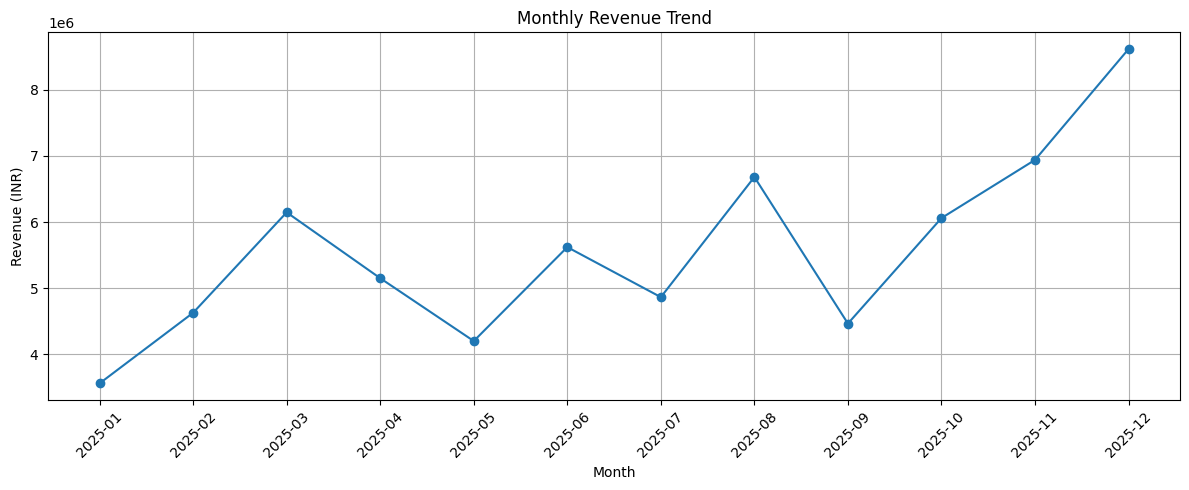

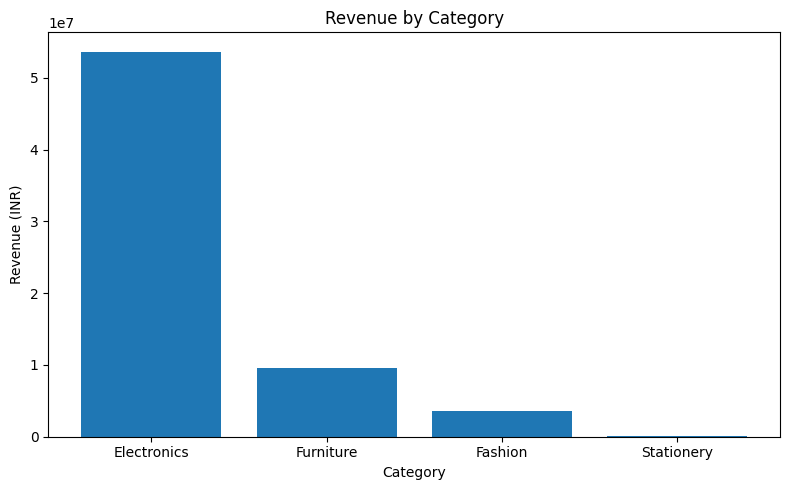

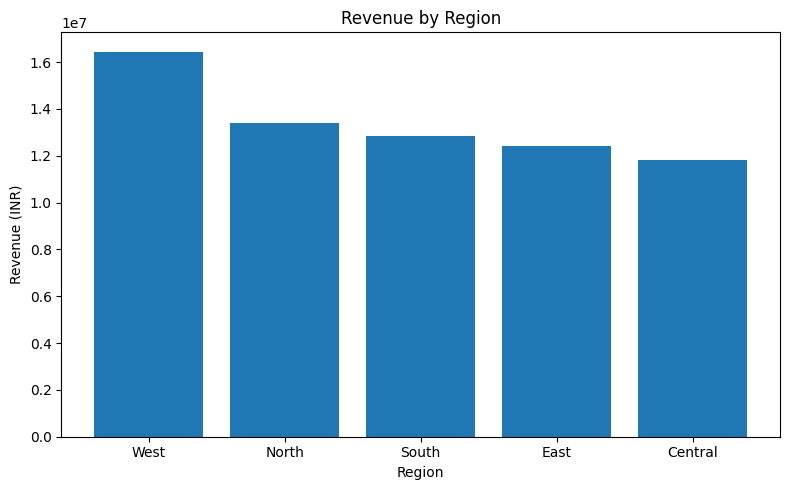

In [ ]:

# Monthly revenue chart
plt.figure(figsize=(12, 5))
plt.plot(
    monthly_analysis["sales_month"],
    monthly_analysis["revenue"],
    marker="o"
)
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

# Category revenue chart
plt.figure(figsize=(8, 5))
plt.bar(category_sales["category"], category_sales["revenue"])
plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (INR)")
plt.tight_layout()
plt.show()

# Regional revenue chart
plt.figure(figsize=(8, 5))
plt.bar(region_analysis["region"], region_analysis["revenue"])
plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue (INR)")
plt.tight_layout()
plt.show()

In [ ]:

# Export analysis tables

outputs = {
    "business_summary.csv": summary,
    "category_sales.csv": category_sales,
    "top_products.csv": top_products,
    "customer_analysis.csv": customer_analysis,
    "monthly_analysis.csv": monthly_analysis,
    "product_ranking.csv": product_ranking,
    "region_analysis.csv": region_analysis
}

for filename, dataframe in outputs.items():
    dataframe.to_csv(filename, index=False)
    print("Saved:", filename)

Saved: business_summary.csv
Saved: category_sales.csv
Saved: top_products.csv
Saved: customer_analysis.csv
Saved: monthly_analysis.csv
Saved: product_ranking.csv
Saved: region_analysis.csv


In [ ]:

sql_text = r"""
-- E-commerce Sales Analysis using SQLite

-- 1. Overall revenue and Average Order Value
SELECT
    COUNT(DISTINCT o.order_id) AS total_orders,
    ROUND(SUM(oi.quantity * p.price), 2) AS total_revenue,
    ROUND(
        SUM(oi.quantity * p.price) * 1.0
        / COUNT(DISTINCT o.order_id), 2
    ) AS average_order_value
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products p ON oi.product_id = p.product_id;

-- 2. Revenue by category
SELECT p.category,
       ROUND(SUM(oi.quantity * p.price), 2) AS revenue
FROM products p
JOIN order_items oi ON p.product_id = oi.product_id
GROUP BY p.category
ORDER BY revenue DESC;

-- 3. Repeat customers
SELECT customer_id, COUNT(*) AS total_orders
FROM orders
GROUP BY customer_id
HAVING COUNT(*) > 1;

-- 4. Monthly revenue
SELECT SUBSTR(o.order_date, 1, 7) AS sales_month,
       ROUND(SUM(oi.quantity * p.price), 2) AS revenue
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products p ON oi.product_id = p.product_id
GROUP BY SUBSTR(o.order_date, 1, 7)
ORDER BY sales_month;

-- 5. Rank products within each category
WITH product_revenue AS (
    SELECT p.product_name, p.category,
           SUM(oi.quantity * p.price) AS revenue
    FROM products p
    JOIN order_items oi ON p.product_id = oi.product_id
    GROUP BY p.product_id, p.product_name, p.category
)
SELECT product_name, category, revenue,
       RANK() OVER (
           PARTITION BY category ORDER BY revenue DESC
       ) AS category_rank
FROM product_revenue;
"""

with open("analysis_queries.sql", "w", encoding="utf-8") as f:
    f.write(sql_text)

print("SQL file created successfully!")

SQL file created successfully!
